# Dagbogen van de zon

Deze notebook gebruikt standaard Jupyter, Matplotlib en ipywidgets en kan in JupyterLab worden uitgevoerd. Selecteer een Python 3.10+ kernel met `numpy`, `matplotlib` en `ipywidgets`, schakel de JupyterLab widget manager in, en voer daarna de notebook van boven naar beneden uit. Installeer ontbrekende pakketten in een notebookcel met `%pip install numpy matplotlib ipywidgets`, herstart daarna de kernel en voer de cellen opnieuw uit.

Kies de breedtegraad van de waarnemer en een datum. De datum bepaalt bij benadering de zonnedeclinatie. De figuren tonen hoe de dagcirkel de horizon doorsnijdt en welk deel boven de horizon ligt.

De dagboogformule is $\\cos(d/2)=-\\tan(\\phi)\\tan(\\delta)$, met $d$ als hoek in graden. De daglengte in uren is $d/15$. De berekening gebruikt een eenvoudige benadering van de zonnedeclinatie en een ideale horizon; atmosferische refractie is niet meegenomen.

## 1. Workspace en notebook

De notebook werkt zelfstandig in JupyterLab of Jupyter Notebook; alle berekeningen en visualisaties staan hieronder. Invoer-, uitvoer-, cache- en logmappen komen onder de gevonden `cursus/` map te staan, of anders onder de kernel's huidige werkmap.

In [106]:
from pathlib import Path

cwd = Path.cwd().resolve()
if cwd.name == "cursus":
    WORKSPACE_DIR = cwd
elif (cwd / "cursus").is_dir():
    WORKSPACE_DIR = cwd / "cursus"
else:
    WORKSPACE_DIR = cwd

print(f"Notebook workspace: {WORKSPACE_DIR}")
print(f"Standalone workspace exists: {WORKSPACE_DIR.is_dir()}")

Notebook workspace: C:\Users\swambecq\astro\cursus
Standalone workspace exists: True


## 2. Omgeving en kernel

De cel controleert de Python-versie en benodigde pakketten. Op een nieuwe omgeving toont hij ook het installatiecommando voor ontbrekende pakketten.

In [107]:
import importlib.metadata
import sys

REQUIRED_PACKAGES = ("numpy", "matplotlib", "ipywidgets")
missing_packages = []
for package_name in REQUIRED_PACKAGES:
    try:
        package_version = importlib.metadata.version(package_name)
        print(f"{package_name}: {package_version}")
    except importlib.metadata.PackageNotFoundError:
        missing_packages.append(package_name)

print(f"Python: {sys.version.split()[0]}")
print(f"Executable: {sys.executable}")
if missing_packages:
    raise ImportError(
        "Missing packages: " + ", ".join(missing_packages)
        + ". Install them with: python -m pip install " + " ".join(missing_packages)
    )

numpy: 2.4.6
matplotlib: 3.11.2
ipywidgets: 8.1.9
Python: 3.11.1
Executable: c:\Users\swambecq\astro\py3.11\Scripts\python.exe


## 3. Paden en runtime-instellingen

Invoer-, uitvoer-, cache- en logmappen komen onder de gevonden `cursus/`-map te staan; als die niet bestaat, gebruikt de notebook de huidige kernelwerkmap.

In [108]:
import random

import matplotlib.pyplot as plt
import numpy as np
from mpl_toolkits.mplot3d.art3d import Poly3DCollection

INPUT_DIR = WORKSPACE_DIR / "input"
OUTPUT_DIR = WORKSPACE_DIR / "output"
CACHE_DIR = WORKSPACE_DIR / "cache"
LOG_DIR = WORKSPACE_DIR / "logs"
for directory in (INPUT_DIR, OUTPUT_DIR, CACHE_DIR, LOG_DIR):
    directory.mkdir(parents=True, exist_ok=True)

DEBUG = False
RANDOM_SEED = 20261005
OVERWRITE_EXPORTS = False
SHOW_GRID = False
DAY_ARC_COLOR = "#e3b522"
HORIZON_COLOR = "#111111"
CONSTRUCTION_COLOR = "#c3c9cc"
OBSERVER_COLOR = "#2e8b57"
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
OBLIQUITY_DEG = 23.43928
YEAR_DAYS = 365.2422

print(f"Output directory: {OUTPUT_DIR}")
print(f"Debug mode: {DEBUG}; random seed: {RANDOM_SEED}")

Output directory: C:\Users\swambecq\astro\cursus\output
Debug mode: False; random seed: 20261005


## 4. Drie aan elkaar gekoppelde aanzichten

Focus een slider en gebruik de pijltjestoetsen om stapsgewijs te veranderen: φ per 0,1° en de datum per dag. De numerieke breedtegraad en kalender blijven gekoppeld.

1. **Waarnemer en aarde:** de aarde staat weer in het midden van het eerste aanzicht. De groene waarnemer staat op het aardoppervlak op breedtegraad $\\phi$; de zenitpijl loopt door de waarnemer. De zwarte horizon gaat door het midden en staat loodrecht op zenit. De hoek van de zon vanaf de equator is de declinatie $\\delta$.
2. **Lokale hemel:** de waarnemer staat als groene stip in het midden van het horizonvlak; zenit staat daar recht boven. De lokale hemel is 45° met de klok mee gedraaid in het horizonvlak: noord wijst schuin rechtsboven en oost schuin rechtsonder. Geel doorgetrokken is dag; geel gestreept is nacht.
3. **Dagboog:** de hoogtegrafiek laat zien welk stuk van de dagelijkse cirkel boven de horizon ligt. De breedtegraad $\\phi$ en declinatie $\\delta$ bepalen samen de daglengte.

In [101]:
from datetime import date
from matplotlib.patches import Circle


def solar_longitude_and_declination(selected_date: date) -> tuple[float, float]:
    """Return approximate solar ecliptic longitude and declination in radians."""
    day_number = selected_date.timetuple().tm_yday
    solar_longitude = 2 * np.pi * (day_number - 80) / YEAR_DAYS
    obliquity = np.deg2rad(OBLIQUITY_DEG)
    declination = np.arcsin(np.sin(obliquity) * np.sin(solar_longitude))
    return solar_longitude, float(declination)


def daylight_hours(latitude_deg: float, declination_rad: float) -> tuple[float, float | None]:
    """Return daylight hours and sunrise hour angle in radians, or None at polar limits."""
    latitude_rad = np.deg2rad(latitude_deg)
    cosine_hour_angle = -np.tan(latitude_rad) * np.tan(declination_rad)
    if cosine_hour_angle <= -1:
        return 24.0, None
    if cosine_hour_angle >= 1:
        return 0.0, None
    hour_angle = float(np.arccos(cosine_hour_angle))
    return 24 * hour_angle / np.pi, hour_angle


def create_day_arc_figure(latitude_deg: float, selected_date: date):
    """Show a 2D Earth meridian, observer's 3D sky, and the visible day arc."""
    solar_longitude, declination_rad = solar_longitude_and_declination(selected_date)
    declination_deg = float(np.rad2deg(declination_rad))
    latitude_rad = np.deg2rad(latitude_deg)
    hours_of_daylight, sunrise_hour_angle = daylight_hours(latitude_deg, declination_rad)

    figure = plt.figure(figsize=(14, 10), facecolor="#f7f8f4", constrained_layout=True)
    layout = figure.add_gridspec(2, 2, height_ratios=(1.15, 0.85))
    earth_axes = figure.add_subplot(layout[0, 0])
    local_axes = figure.add_subplot(layout[0, 1], projection="3d")
    sky_axes = figure.add_subplot(layout[1, :])

    # The flat Earth meridian shows latitude and declination without a projected ecliptic.
    earth_axes.add_patch(Circle((0, 0), 1, fill=False, color="#aab8b8", linewidth=1.2))
    earth_axes.axhline(0, color="#347b8c", linewidth=1.8, label="Hemelequator")
    earth_axes.axvline(0, color=CONSTRUCTION_COLOR, linewidth=1.4, label="Aardas / hemelpoolas")

    earth_radius = 0.22
    earth_axes.add_patch(Circle((0, 0), earth_radius, facecolor="#5896aa",
                                edgecolor="#315968", linewidth=1.0, alpha=0.9))
    earth_axes.plot([-earth_radius, earth_radius], [0, 0], color="#d4e5e3", linewidth=1.2)

    observer_position = np.array((earth_radius * np.cos(latitude_rad),
                                  earth_radius * np.sin(latitude_rad)))
    observer_zenith = np.array((np.cos(latitude_rad), np.sin(latitude_rad)))
    horizon_direction = np.array((-np.sin(latitude_rad), np.cos(latitude_rad)))
    earth_axes.scatter(*observer_position, color="#f4f1e8", edgecolor="#25383d",
                       s=38, zorder=5, label=f"Waarnemer (φ={latitude_deg:.1f}°)")

    # Zenith runs from Earth's center through the observer to the celestial sphere.
    zenith_tip = observer_zenith * 1.06
    earth_axes.annotate("", xy=zenith_tip, xytext=(0, 0),
                        arrowprops={"arrowstyle": "-|>", "color": "#263238", "lw": 1.8})
    earth_axes.text(*(zenith_tip + np.array((0.02, 0.015))), "Zenit", fontsize=8)

    # The local horizon is tangent to Earth at the observer and perpendicular to zenith.
    horizon_half_width = np.sqrt(1 - earth_radius**2)
    horizon_start = observer_position - horizon_half_width * horizon_direction
    horizon_end = observer_position + horizon_half_width * horizon_direction
    earth_axes.plot([horizon_start[0], horizon_end[0]],
                    [horizon_start[1], horizon_end[1]],
                    color=HORIZON_COLOR, linewidth=1.8, label="Lokale horizon", zorder=3)

    # φ is latitude; δ is the Sun's angular distance north or south of the equator.
    phi_arc = np.linspace(0, latitude_rad, 60)
    earth_axes.plot(0.39 * np.cos(phi_arc), 0.39 * np.sin(phi_arc),
                    color="#347b8c", linewidth=2.2)
    phi_label_angle = latitude_rad / 2
    earth_axes.text(0.47 * np.cos(phi_label_angle), 0.47 * np.sin(phi_label_angle),
                    "φ", color="#246777", fontsize=12, weight="bold")

    sun_position = np.array((np.cos(declination_rad), np.sin(declination_rad)))
    earth_axes.plot([0, sun_position[0]], [0, sun_position[1]],
                    color=CONSTRUCTION_COLOR, linewidth=2.0, label="Richting naar de zon")
    earth_axes.scatter(*sun_position, color=DAY_ARC_COLOR, edgecolor="#6d4d12",
                       s=75, zorder=5, label="Zon")
    earth_axes.plot([sun_position[0], sun_position[0]], [0, sun_position[1]],
                    color=CONSTRUCTION_COLOR, linestyle="--", linewidth=1.2)
    delta_arc = np.linspace(0, declination_rad, 60)
    earth_axes.plot(0.70 * np.cos(delta_arc), 0.70 * np.sin(delta_arc),
                    color=CONSTRUCTION_COLOR, linewidth=2.2)
    delta_label_angle = declination_rad / 2
    earth_axes.text(0.78 * np.cos(delta_label_angle), 0.78 * np.sin(delta_label_angle),
                    "δ", color=CONSTRUCTION_COLOR, fontsize=12, weight="bold")

    earth_axes.text(0, 1.06, "Noordelijke hemelpool", ha="center", fontsize=8)
    earth_axes.text(-0.02, -1.12, "Zuidelijke hemelpool", ha="center", fontsize=8)
    earth_axes.text(-0.96, 0.04, "Equator", ha="left", color="#246777", fontsize=8)
    earth_axes.text(-0.95, -0.28, "Aarde (schematisch)", ha="left", fontsize=8)
    earth_axes.set(xlim=(-1.2, 1.2), ylim=(-1.2, 1.2), aspect="equal")
    earth_axes.set_xlabel("Richting langs hemelequator")
    earth_axes.set_ylabel("Declinatie")
    earth_axes.set_xticks([])
    earth_axes.set_yticks([])
    earth_axes.grid(False)
    earth_axes.set_title("1. Aarde-frame: φ, δ en horizon",
                         pad=10, fontsize=11, weight="bold")
    earth_axes.legend(loc="lower left", fontsize=7, frameon=True)

    # Observer frame: local east, north, and up coordinates; horizon is z=0.
    sphere_angle = np.linspace(0, 2 * np.pi, 70)
    sphere_latitude = np.linspace(-np.pi / 2, np.pi / 2, 30)
    local_x = np.outer(np.cos(sphere_angle), np.cos(sphere_latitude))
    local_y = np.outer(np.sin(sphere_angle), np.cos(sphere_latitude))
    local_z = np.outer(np.ones_like(sphere_angle), np.sin(sphere_latitude))
    local_axes.plot_surface(local_x, local_y, local_z, color="#b8d9dd", alpha=0.10,
                            linewidth=0)
    horizon_angle = np.linspace(0, 2 * np.pi, 180)
    horizon_x = np.cos(horizon_angle)
    horizon_y = np.sin(horizon_angle)
    local_axes.add_collection3d(Poly3DCollection(
        [list(zip(horizon_x, horizon_y, np.zeros_like(horizon_angle)))],
        facecolor="#d4e5e3", edgecolor="none", alpha=0.12,
    ))
    local_axes.plot(horizon_x, horizon_y, np.zeros_like(horizon_angle),
                    color=HORIZON_COLOR, linewidth=1.8, label="Lokale horizon")

    daily_hour_angle = np.linspace(-np.pi, np.pi, 600)
    daily_east = -np.cos(declination_rad) * np.sin(daily_hour_angle)
    daily_north = (
        np.cos(latitude_rad) * np.sin(declination_rad)
        - np.sin(latitude_rad) * np.cos(declination_rad) * np.cos(daily_hour_angle)
    )
    daily_up = (
        np.sin(latitude_rad) * np.sin(declination_rad)
        + np.cos(latitude_rad) * np.cos(declination_rad) * np.cos(daily_hour_angle)
    )
    above_horizon = daily_up >= 0
    local_axes.plot(np.where(above_horizon, daily_east, np.nan),
                    np.where(above_horizon, daily_north, np.nan),
                    np.where(above_horizon, daily_up, np.nan),
                    color=DAY_ARC_COLOR, linewidth=3, linestyle="-",
                    label="Dagboog (dag)")
    local_axes.plot(np.where(~above_horizon, daily_east, np.nan),
                    np.where(~above_horizon, daily_north, np.nan),
                    np.where(~above_horizon, daily_up, np.nan),
                    color=DAY_ARC_COLOR, linewidth=2, linestyle="--",
                    label="Dagboog (nacht)")
    local_axes.scatter([0], [0], [1], color="#263238", s=24, depthshade=False)
    local_axes.text(0, 0, 1.10, "Zenit", ha="center", fontsize=8)
    local_axes.scatter([0], [np.cos(latitude_rad)], [np.sin(latitude_rad)],
                       color="#347b8c", s=30, depthshade=False)
    local_axes.text(0, np.cos(latitude_rad) * 1.10, np.sin(latitude_rad) * 1.10,
                    "Hemelpool", color="#347b8c", fontsize=8)
    noon_north = np.cos(latitude_rad) * np.sin(declination_rad) - np.sin(latitude_rad) * np.cos(declination_rad)
    noon_up = np.sin(latitude_rad) * np.sin(declination_rad) + np.cos(latitude_rad) * np.cos(declination_rad)
    local_axes.scatter([0], [noon_north], [noon_up], color=DAY_ARC_COLOR,
                       edgecolor="#6d4d12", s=65, depthshade=False, label="Zon (middag)")
    local_axes.set(xlim=(-1.08, 1.08), ylim=(-1.08, 1.08), zlim=(-1.08, 1.08))
    local_axes.set_box_aspect((1, 1, 1))
    local_axes.set_xlabel("Oost")
    local_axes.set_ylabel("Noord")
    local_axes.set_zlabel("Omhoog")
    local_axes.set_xticks([])
    local_axes.set_yticks([])
    local_axes.set_zticks([])
    local_axes.view_init(elev=24, azim=-48)
    local_axes.set_title("2. Waarnemers-frame: horizon en dagcirkel",
                         pad=10, fontsize=11, weight="bold")
    local_axes.legend(loc="lower left", fontsize=7, frameon=True)
    local_axes.grid(False)

    local_solar_time = np.linspace(0, 24, 721)
    hour_angle = np.deg2rad((local_solar_time - 12) * 15)
    altitude_sine = (
        np.sin(latitude_rad) * np.sin(declination_rad)
        + np.cos(latitude_rad) * np.cos(declination_rad) * np.cos(hour_angle)
    )
    altitude_deg = np.rad2deg(np.arcsin(np.clip(altitude_sine, -1, 1)))
    sky_axes.axhline(0, color=HORIZON_COLOR, linewidth=1.6, label="Lokale horizon")
    sky_axes.plot(local_solar_time, altitude_deg, color="#9aa7a7", linewidth=1.4,
                  label="Volledige dagcirkel")
    sky_axes.fill_between(local_solar_time, 0, altitude_deg, where=altitude_deg >= 0,
                          color=DAY_ARC_COLOR, alpha=0.26, interpolate=True)
    sky_axes.plot(local_solar_time, np.where(altitude_deg >= 0, altitude_deg, np.nan),
                  color=DAY_ARC_COLOR, linewidth=3, label="Zichtbare dagboog")
    sky_axes.scatter([12], [float(np.max(altitude_deg))], color=DAY_ARC_COLOR, s=48,
                     zorder=4, label="Zonnemiddag")

    if sunrise_hour_angle is not None:
        hour_angle_deg = np.rad2deg(sunrise_hour_angle)
        sunrise_time = 12 - hour_angle_deg / 15
        sunset_time = 12 + hour_angle_deg / 15
        sky_axes.axvline(sunrise_time, color="#637477", linestyle=":", linewidth=1)
        sky_axes.axvline(sunset_time, color="#637477", linestyle=":", linewidth=1)
        sky_axes.text(sunrise_time, 4, f"{sunrise_time:.1f} u", rotation=90,
                      va="bottom", ha="right", fontsize=8)
        sky_axes.text(sunset_time, 4, f"{sunset_time:.1f} u", rotation=90,
                      va="bottom", ha="left", fontsize=8)
        condition = f"Opkomst {sunrise_time:.2f} u  |  ondergang {sunset_time:.2f} u"
    else:
        condition = "Pooldag: zon gaat niet onder" if hours_of_daylight == 24 else "Poolnacht: zon komt niet op"
        sky_axes.text(12, 7 if hours_of_daylight == 24 else -7, condition, ha="center", fontsize=10)

    sky_axes.set(xlim=(0, 24), ylim=(-10, 90), xticks=np.arange(0, 25, 4),
                 xlabel="Lokale zonnetijd (uren)",
                 ylabel="Zonnehoogte boven lokale horizon (graden)")
    sky_axes.set_title("3. Dagboog: zichtbaar deel bepaalt de daglengte",
                       pad=10, fontsize=11, weight="bold")
    sky_axes.grid(True, alpha=0.22)
    sky_axes.legend(loc="upper right", fontsize=8, ncol=2)

    figure.suptitle(
        f"{selected_date:%d %B %Y}  |  φ = {latitude_deg:.1f}°  |  "
        f"δ = {declination_deg:+.2f}°  |  Daglengte {hours_of_daylight:.2f} uur",
        fontsize=14, weight="bold",
    )
    summary = {
        "date": selected_date.isoformat(),
        "latitude_deg": float(latitude_deg),
        "solar_declination_deg": declination_deg,
        "daylight_hours": float(hours_of_daylight),
        "sunrise_hour_angle_deg": None if sunrise_hour_angle is None else float(np.rad2deg(sunrise_hour_angle)),
        "condition": condition,
    }
    return figure, summary

In [140]:
def add_earth_frame_day_arc(figure, latitude_deg: float, declination_deg: float) -> None:
    """Draw a centered Earth section with the observer frame rotated in the horizon plane."""
    declination_rad = np.deg2rad(declination_deg)
    latitude_rad = np.deg2rad(latitude_deg)
    chord_y = np.sin(declination_rad)
    chord_half_width = np.cos(declination_rad)
    earth_radius = 0.22
    earth_axes = figure.axes[0]
    local_axes = figure.axes[1]
    earth_axes.clear()

    observer_zenith = np.array((np.cos(latitude_rad), np.sin(latitude_rad)))
    horizon_direction = np.array((-np.sin(latitude_rad), np.cos(latitude_rad)))
    sun_direction = np.array((np.cos(declination_rad), np.sin(declination_rad)))
    observer_position = earth_radius * observer_zenith

    earth_axes.add_patch(Circle((0, 0), 1, fill=False, color="#aab8b8", linewidth=1.2))
    earth_axes.axhline(0, color="#347b8c", linewidth=1.8, label="Hemelequator")
    earth_axes.axvline(0, color=CONSTRUCTION_COLOR, linewidth=1.4, label="Hemelpoolas")
    earth_axes.add_patch(Circle((0, 0), earth_radius, facecolor="#5896aa",
                                edgecolor="#315968", linewidth=1.0, alpha=0.9))
    earth_axes.plot([-earth_radius, earth_radius], [0, 0], color="#d4e5e3", linewidth=1.2)
    earth_axes.plot([0, 0], [-earth_radius, earth_radius], color=CONSTRUCTION_COLOR, linewidth=1.2)

    earth_axes.scatter(*observer_position, color=OBSERVER_COLOR, edgecolor="#174b30",
                       s=48, zorder=7, label="Waarnemer")
    zenith_tip = observer_zenith * 1.06
    earth_axes.annotate("", xy=zenith_tip, xytext=(0, 0),
                        arrowprops={"arrowstyle": "-|>", "color": "#263238", "lw": 1.8})
    earth_axes.text(*(zenith_tip + np.array((0.02, 0.015))), "Zenit", fontsize=8)

    earth_axes.plot([-horizon_direction[0], horizon_direction[0]],
                    [-horizon_direction[1], horizon_direction[1]],
                    color=HORIZON_COLOR, linewidth=1.8, label="Lokale horizon", zorder=3)

    phi_arc = np.linspace(0, latitude_rad, 60)
    earth_axes.plot(0.39 * np.cos(phi_arc), 0.39 * np.sin(phi_arc),
                    color="#347b8c", linewidth=2.2)
    phi_label_angle = latitude_rad / 2
    earth_axes.text(0.47 * np.cos(phi_label_angle), 0.47 * np.sin(phi_label_angle),
                    "φ", color="#246777", fontsize=12, weight="bold")

    sun_position = sun_direction * 0.96
    earth_axes.plot([0, sun_position[0]], [0, sun_position[1]],
                    color=CONSTRUCTION_COLOR, linewidth=2.0, label="Zonrichting")
    earth_axes.scatter(*sun_position, color=DAY_ARC_COLOR, edgecolor="#6d4d12",
                       s=75, zorder=6, label="Zon")
    delta_arc = np.linspace(0, declination_rad, 60)
    earth_axes.plot(0.70 * np.cos(delta_arc), 0.70 * np.sin(delta_arc),
                    color=CONSTRUCTION_COLOR, linewidth=2.2)
    delta_label_angle = declination_rad / 2
    earth_axes.text(0.78 * np.cos(delta_label_angle), 0.78 * np.sin(delta_label_angle),
                    "δ", color=CONSTRUCTION_COLOR, fontsize=12, weight="bold")

    earth_axes.text(-0.28, -0.28, "Aarde", fontsize=8)
    earth_axes.text(0, 1.06, "Noordelijke hemelpool", ha="center", fontsize=8)
    earth_axes.text(-0.02, -1.12, "Zuidelijke hemelpool", ha="center", fontsize=8)
    earth_axes.set(xlim=(-1.2, 1.2), ylim=(-1.2, 1.2), aspect="equal")
    earth_axes.set_xlabel("Equatorrichting")
    earth_axes.set_ylabel("Hemelpoolrichting")
    earth_axes.set_xticks([])
    earth_axes.set_yticks([])
    earth_axes.grid(False)
    earth_axes.set_title("1. Aarde gecentreerd: waarnemer op φ",
                         pad=10, fontsize=10, weight="bold")

    local_axes.scatter([0], [0], [0], color=OBSERVER_COLOR, edgecolor="#174b30",
                       s=48, depthshade=False, label="Waarnemer")
    local_axes.quiver(0, 0, 0, 0, 1, 0, length=0.78, normalize=True,
                      color="#347b8c", arrow_length_ratio=0.14, linewidth=1.8)
    local_axes.text(0, 0.82, 0, "Noord", color="#246777", fontsize=8)
    local_axes.view_init(elev=24, azim=-45, roll=0)
    local_axes.set_xlabel("Oost")
    local_axes.set_ylabel("Noord")
    local_axes.legend(loc="lower left", fontsize=7, frameon=True)

    horizon_crossing_x = np.clip(
        -np.tan(latitude_rad) * np.sin(declination_rad),
        -chord_half_width,
        chord_half_width,
    )
    arc_sections = (
        ("Dagboog (nacht)", -chord_half_width, horizon_crossing_x, "--"),
        ("Dagboog (dag)", horizon_crossing_x, chord_half_width, "-"),
    )

    def exclude_earth(start_x: float, end_x: float) -> list[tuple[float, float]]:
        if start_x >= end_x:
            return []
        if abs(chord_y) >= earth_radius:
            return [(start_x, end_x)]
        earth_edge = np.sqrt(earth_radius**2 - chord_y**2)
        visible_parts = []
        if start_x < -earth_edge:
            visible_parts.append((start_x, min(end_x, -earth_edge)))
        if end_x > earth_edge:
            visible_parts.append((max(start_x, earth_edge), end_x))
        return [(left, right) for left, right in visible_parts if left < right]

    for label, start_x, end_x, linestyle in arc_sections:
        for segment_index, (left, right) in enumerate(exclude_earth(start_x, end_x)):
            earth_axes.plot(
                [left, right], [chord_y, chord_y],
                color=DAY_ARC_COLOR, linestyle=linestyle, linewidth=2.6,
                label=label if segment_index == 0 else None,
                zorder=4,
            )
    earth_axes.legend(loc="lower left", fontsize=7, frameon=True)

HTML(value='')

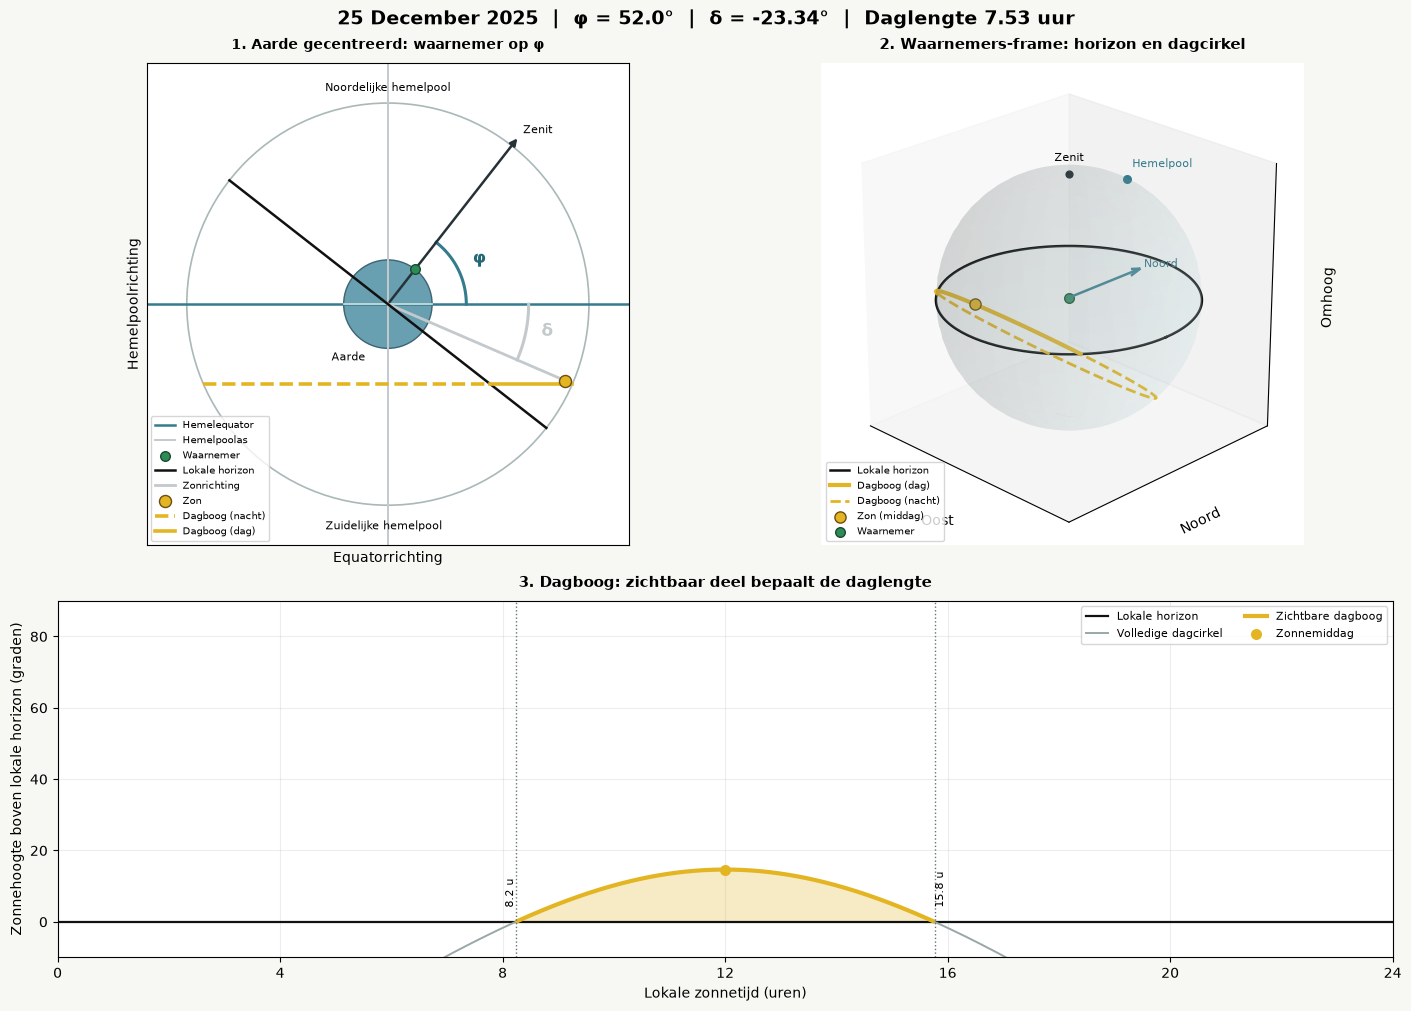

In [ ]:
from datetime import timedelta

import ipywidgets as widgets
from IPython.display import display

latitude_control = widgets.FloatSlider(
    value=52.0, min=-90.0, max=90.0, step=0.1,
    description="φ:", readout_format=".1f",
    continuous_update=False, style={"description_width": "initial"},
    layout=widgets.Layout(width="430px"),
)
latitude_input = widgets.BoundedFloatText(
    value=latitude_control.value, min=latitude_control.min, max=latitude_control.max,
    step=latitude_control.step, description="°",
    style={"description_width": "initial"},
    layout=widgets.Layout(width="130px"),
)


def sync_latitude_input(change):
    latitude_input.value = change["new"]


def sync_latitude_slider(change):
    latitude_control.value = change["new"]


latitude_control.observe(sync_latitude_input, names="value")
latitude_input.observe(sync_latitude_slider, names="value")

date_control = widgets.DatePicker(
    description="Kalender:", value=date(2026, 3, 20),
    style={"description_width": "initial"},
    layout=widgets.Layout(width="260px"),
)
initial_year_days = (date(date_control.value.year + 1, 1, 1) - date(date_control.value.year, 1, 1)).days
day_of_year_control = widgets.IntSlider(
    value=date_control.value.timetuple().tm_yday,
    min=1, max=initial_year_days, step=1,
    description="Dagnummer:", continuous_update=False,
    style={"description_width": "initial"},
    layout=widgets.Layout(width="430px"),
)


def sync_date_from_day_number(change):
    current_date = date_control.value or date(2026, 1, 1)
    date_control.value = date(current_date.year, 1, 1) + timedelta(days=change["new"] - 1)


def sync_day_number_from_date(change):
    selected_date = change["new"]
    if selected_date is None:
        return
    days_in_year = (date(selected_date.year + 1, 1, 1) - date(selected_date.year, 1, 1)).days
    day_of_year_control.unobserve(sync_date_from_day_number, names="value")
    day_of_year_control.max = days_in_year
    day_of_year_control.value = selected_date.timetuple().tm_yday
    day_of_year_control.observe(sync_date_from_day_number, names="value")


day_of_year_control.observe(sync_date_from_day_number, names="value")
date_control.observe(sync_day_number_from_date, names="value")

figure_display_handle = None
summary_output = widgets.HTML()


def update_visualization(latitude_deg: float, selected_date: date | None) -> None:
    global figure_display_handle
    if selected_date is None:
        return
    figure, summary = create_day_arc_figure(latitude_deg, selected_date)
    add_earth_frame_day_arc(
        figure, latitude_deg, summary["solar_declination_deg"]
    )
    if figure_display_handle is None:
        figure_display_handle = display(figure, display_id=True)
    else:
        figure_display_handle.update(figure)
    plt.close(figure)
    summary_output.value = (
        f"φ = {summary['latitude_deg']:.1f}°  |  "
        f"δ = {summary['solar_declination_deg']:+.2f}°  |  "
        f"Daglengte = {summary['daylight_hours']:.2f} uur  |  {summary['condition']}"
    )


def update_visualization_from_latitude(change):
    update_visualization(change["new"], date_control.value)


def update_visualization_from_date(change):
    update_visualization(latitude_control.value, change["new"])


latitude_control.observe(update_visualization_from_latitude, names="value")
date_control.observe(update_visualization_from_date, names="value")
controls = widgets.VBox([
    widgets.HBox([latitude_control, latitude_input]),
    widgets.HBox([day_of_year_control, date_control]),
])
display(controls, summary_output)
update_visualization(latitude_control.value, date_control.value)

## 5. Resultaten lokaal opslaan

Deze cel exporteert de geselecteerde situatie als PNG, JSON en CSV naar `cursus/output/`. Bestandsnamen bevatten standaard een tijdstempel; zet `OVERWRITE_EXPORTS=True` in de configuratiecel om steeds dezelfde bestanden te vervangen.

In [141]:
import csv
import json
from datetime import datetime, timezone

selected_latitude = float(latitude_control.value)
selected_date = date_control.value or date(2026, 3, 20)
export_figure, export_summary = create_day_arc_figure(selected_latitude, selected_date)
add_earth_frame_day_arc(
    export_figure, selected_latitude, export_summary["solar_declination_deg"]
)
timestamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")
artifact_name = "dagboog" if OVERWRITE_EXPORTS else f"dagboog_{timestamp}"

plot_path = OUTPUT_DIR / f"{artifact_name}.png"
json_path = OUTPUT_DIR / f"{artifact_name}.json"
csv_path = OUTPUT_DIR / f"{artifact_name}.csv"
export_figure.savefig(plot_path, dpi=160, bbox_inches="tight")
plt.close(export_figure)
with json_path.open("w", encoding="utf-8") as json_file:
    json.dump(export_summary, json_file, indent=2, ensure_ascii=False)
with csv_path.open("w", newline="", encoding="utf-8") as csv_file:
    writer = csv.DictWriter(csv_file, fieldnames=export_summary.keys())
    writer.writeheader()
    writer.writerow(export_summary)

print(f"PNG: {plot_path}")
print(f"JSON: {json_path}")
print(f"CSV: {csv_path}")

PNG: C:\Users\swambecq\astro\cursus\output\dagboog_20261005T195616Z.png
JSON: C:\Users\swambecq\astro\cursus\output\dagboog_20261005T195616Z.json
CSV: C:\Users\swambecq\astro\cursus\output\dagboog_20261005T195616Z.csv


## 6. Herhaalbaarheid en rooktests

Snelle controles voor de equinox, zomer- en winterdag op 52° noorderbreedte en pooldag/-nacht. Ook worden de exportbestanden gecontroleerd.

In [142]:
from matplotlib.colors import to_rgba
from mpl_toolkits.mplot3d import proj3d

equinox_date = date(2026, 3, 20)
summer_date = date(2026, 6, 21)
winter_date = date(2026, 12, 21)

_, equinox_declination = solar_longitude_and_declination(equinox_date)
_, summer_declination = solar_longitude_and_declination(summer_date)
_, winter_declination = solar_longitude_and_declination(winter_date)
equinox_daylight, _ = daylight_hours(0, equinox_declination)
high_latitude_summer, _ = daylight_hours(52, summer_declination)
high_latitude_winter, _ = daylight_hours(52, winter_declination)
pole_summer, _ = daylight_hours(90, summer_declination)
pole_winter, _ = daylight_hours(90, winter_declination)
selected_declination = np.deg2rad(export_summary["solar_declination_deg"])
selected_daylight, _ = daylight_hours(selected_latitude, selected_declination)

earth_axes = export_figure.axes[0]
local_axes = export_figure.axes[1]
earth_day_night_lines = [
    line for line in earth_axes.lines
    if line.get_color() == DAY_ARC_COLOR
]
local_day_line = next(line for line in local_axes.lines if line.get_label() == "Dagboog (dag)")
local_night_line = next(line for line in local_axes.lines if line.get_label() == "Dagboog (nacht)")
earth_observer_dot = next(
    collection for collection in earth_axes.collections
    if collection.get_label() == "Waarnemer"
)
local_observer_dot = next(
    collection for collection in local_axes.collections
    if collection.get_label() == "Waarnemer"
)
expected_chord_height = np.sin(selected_declination)
horizon_crossing_x = -np.tan(np.deg2rad(selected_latitude)) * expected_chord_height
horizon_line = next(line for line in earth_axes.lines if line.get_label() == "Lokale horizon")
horizon_vector = np.array((
    horizon_line.get_xdata()[1] - horizon_line.get_xdata()[0],
    horizon_line.get_ydata()[1] - horizon_line.get_ydata()[0],
))
horizon_midpoint = np.array((
    np.mean(horizon_line.get_xdata()),
    np.mean(horizon_line.get_ydata()),
))
zenith_direction = np.array((
    np.cos(np.deg2rad(selected_latitude)),
    np.sin(np.deg2rad(selected_latitude)),
))
north_screen_x, north_screen_y, _ = proj3d.proj_transform(0, 1, 0, local_axes.get_proj())
east_screen_x, east_screen_y, _ = proj3d.proj_transform(1, 0, 0, local_axes.get_proj())
center_screen_x, center_screen_y, _ = proj3d.proj_transform(0, 0, 0, local_axes.get_proj())

reference_figure, reference_summary = create_day_arc_figure(52, equinox_date)
add_earth_frame_day_arc(reference_figure, 52, reference_summary["solar_declination_deg"])
reference_lines = [
    line for line in reference_figure.axes[0].lines
    if line.get_color() == DAY_ARC_COLOR
]
reference_horizon_crossing = -np.tan(np.deg2rad(52)) * np.sin(
    np.deg2rad(reference_summary["solar_declination_deg"])
)

assert abs(equinox_daylight - 12) < 0.1, equinox_daylight
assert 16 < high_latitude_summer < 17, high_latitude_summer
assert 7 < high_latitude_winter < 8, high_latitude_winter
assert pole_summer == 24, pole_summer
assert pole_winter == 0, pole_winter
assert len(export_figure.axes) == 3
assert np.allclose(horizon_midpoint, (0, 0))
assert abs(np.dot(horizon_vector, zenith_direction)) < 1e-9
assert horizon_line.get_color() == HORIZON_COLOR
assert any(line.get_label() == "Lokale horizon" and line.get_color() == HORIZON_COLOR
           for line in local_axes.lines)
assert any(line.get_label() == "Zonrichting" and line.get_color() == CONSTRUCTION_COLOR
           for line in earth_axes.lines)
assert np.allclose(earth_observer_dot.get_facecolor()[0], to_rgba(OBSERVER_COLOR))
assert np.allclose(local_observer_dot.get_facecolor()[0], to_rgba(OBSERVER_COLOR))
expected_observer_position = 0.22 * zenith_direction
assert np.allclose(earth_observer_dot.get_offsets(), [expected_observer_position])
assert np.allclose([np.asarray(axis).reshape(-1)[0] for axis in local_observer_dot._offsets3d], (0, 0, 0))
assert np.isclose(local_axes.azim, -45)
assert np.isclose(local_axes.roll, 0)
assert north_screen_x > center_screen_x and north_screen_y > center_screen_y
assert east_screen_x > center_screen_x and east_screen_y < center_screen_y
assert all(np.allclose(line.get_ydata(), expected_chord_height) for line in earth_day_night_lines)
assert local_day_line.get_color() == DAY_ARC_COLOR and local_day_line.get_linestyle() == "-"
assert local_night_line.get_color() == DAY_ARC_COLOR and local_night_line.get_linestyle() == "--"

current_solid_lines = [line for line in earth_day_night_lines if line.get_linestyle() == "-"]
current_dashed_lines = [line for line in earth_day_night_lines if line.get_linestyle() == "--"]
if selected_daylight == 24:
    assert current_solid_lines and not current_dashed_lines
elif selected_daylight == 0:
    assert current_dashed_lines and not current_solid_lines
else:
    assert current_solid_lines and current_dashed_lines

assert any(line.get_linestyle() == "-" for line in reference_lines)
assert any(line.get_linestyle() == "--" for line in reference_lines)
assert all(
    np.all(line.get_xdata() >= reference_horizon_crossing - 1e-9)
    for line in reference_lines if line.get_linestyle() == "-"
)
assert all(
    np.all(line.get_xdata() <= reference_horizon_crossing + 1e-9)
    for line in reference_lines if line.get_linestyle() == "--"
)
plt.close(reference_figure)
assert all(path.is_file() and path.stat().st_size > 0 for path in (plot_path, json_path, csv_path))

print("PASS: equinox, seasonal daylight, and polar day/night")
print("PASS: Earth centered with observer on its surface")
print("PASS: local horizon-plane view rotated 45 degrees clockwise")
print("PASS: horizon through center and matching solid-day/dashed-night paths")
print(f"PASS: exports exist ({plot_path.name}, {json_path.name}, {csv_path.name})")
print(f"52° N daylight: summer {high_latitude_summer:.2f} h; winter {high_latitude_winter:.2f} h")

PASS: equinox, seasonal daylight, and polar day/night
PASS: Earth centered with observer on its surface
PASS: local horizon-plane view rotated 45 degrees clockwise
PASS: horizon through center and matching solid-day/dashed-night paths
PASS: exports exist (dagboog_20261005T195616Z.png, dagboog_20261005T195616Z.json, dagboog_20261005T195616Z.csv)
52° N daylight: summer 16.49 h; winter 7.51 h


In [115]:
north_arrow_collections = [
    collection for collection in local_axes.collections
    if hasattr(collection, "_segments3d")
]
assert north_arrow_collections
assert any(text.get_text() == "Noord" for text in local_axes.texts)
print("PASS: local north arrow starts at observer and is labeled")

PASS: local north arrow starts at observer and is labeled
